# Task 1: Foundational Setup & Exploratory Data Analysis (EDA)

**Dataset:** Sample Superstore Sales (`data/superstore_cleaned.csv` & `data/superstore.db`)  
**Objective:** Verify the analytics environment, inspect the cleaned dataset, query via SQLAlchemy, and uncover key sales, profit, regional, and discounting insights.

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
from sqlalchemy import create_engine, text

sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams["figure.dpi"] = 110

DATA_DIR = Path("../data")
REPORTS_DIR = Path("../reports")
REPORTS_DIR.mkdir(parents=True, exist_ok=True)

df = pd.read_csv(DATA_DIR / "superstore_cleaned.csv", parse_dates=["order_date", "ship_date"], dtype={"postal_code": str})
print(f"Dataset shape: {df.shape[0]} rows x {df.shape[1]} columns")
df.head(3)

Dataset shape: 9993 rows x 28 columns


,row_id,order_id,order_date,ship_date,ship_mode,customer_id,customer_name,segment,country,city,...,quantity,discount,profit,order_year,order_month,order_year_month,order_quarter,shipping_days,profit_margin,is_profitable
0,1,CA-2017-152156,2017-11-08,2017-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,2.0,0.0,41.9136,2017,11,2017-11,2017Q4,3,0.16,True
1,2,CA-2017-152156,2017-11-08,2017-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,3.0,0.0,219.5820,2017,11,2017-11,2017Q4,3,0.30,True
2,3,CA-2017-138688,2017-06-12,2017-06-16,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,2.0,0.0,6.8714,2017,6,2017-06,2017Q2,4,0.47,True


## 1. Data Quality & KPI Overview

In [2]:
print("Missing values per column:")
print(df.isna().sum().to_string())
print("\nDate Range:", df["order_date"].min().date(), "to", df["order_date"].max().date())

total_sales = df["sales"].sum()
total_profit = df["profit"].sum()
total_orders = df["order_id"].nunique()
total_customers = df["customer_id"].nunique()
overall_margin = (total_profit / total_sales) * 100

print(f"\nTotal Sales:     ${total_sales:,.2f}")
print(f"Total Profit:    ${total_profit:,.2f}")
print(f"Profit Margin:   {overall_margin:.2f}%")
print(f"Unique Orders:   {total_orders:,}")
print(f"Unique Customers:{total_customers:,}")
df[["sales", "quantity", "discount", "profit", "shipping_days", "profit_margin"]].describe().round(2)

Missing values per column:
row_id              0
order_id            0
order_date          0
ship_date           0
ship_mode           0
customer_id         0
customer_name       0
segment             0
country             0
city                0
state               0
postal_code         0
region              0
product_id          0
category            0
sub_category        0
product_name        0
sales               0
quantity            0
discount            0
profit              0
order_year          0
order_month         0
order_year_month    0
order_quarter       0
shipping_days       0
profit_margin       0
is_profitable       0

Date Range: 2015-01-03 to 2018-12-30

Total Sales:     $2,296,919.49
Total Profit:    $286,409.08
Profit Margin:   12.47%
Unique Orders:   5,009
Unique Customers:793


,sales,quantity,discount,profit,shipping_days,profit_margin
count,9993.00,9993.00,9993.00,9993.00,9993.00,9993.00
mean,229.85,3.79,0.16,28.66,3.96,0.12
std,623.28,2.23,0.21,234.27,1.75,0.47
min,0.44,1.00,0.00,-6599.98,0.00,-2.75
25%,17.28,2.00,0.00,1.73,3.00,0.08
50%,54.48,3.00,0.20,8.67,4.00,0.27
75%,209.94,5.00,0.20,29.36,5.00,0.36
max,22638.48,14.00,0.80,8399.98,7.00,0.50


## 2. Category & Sub-Category Performance

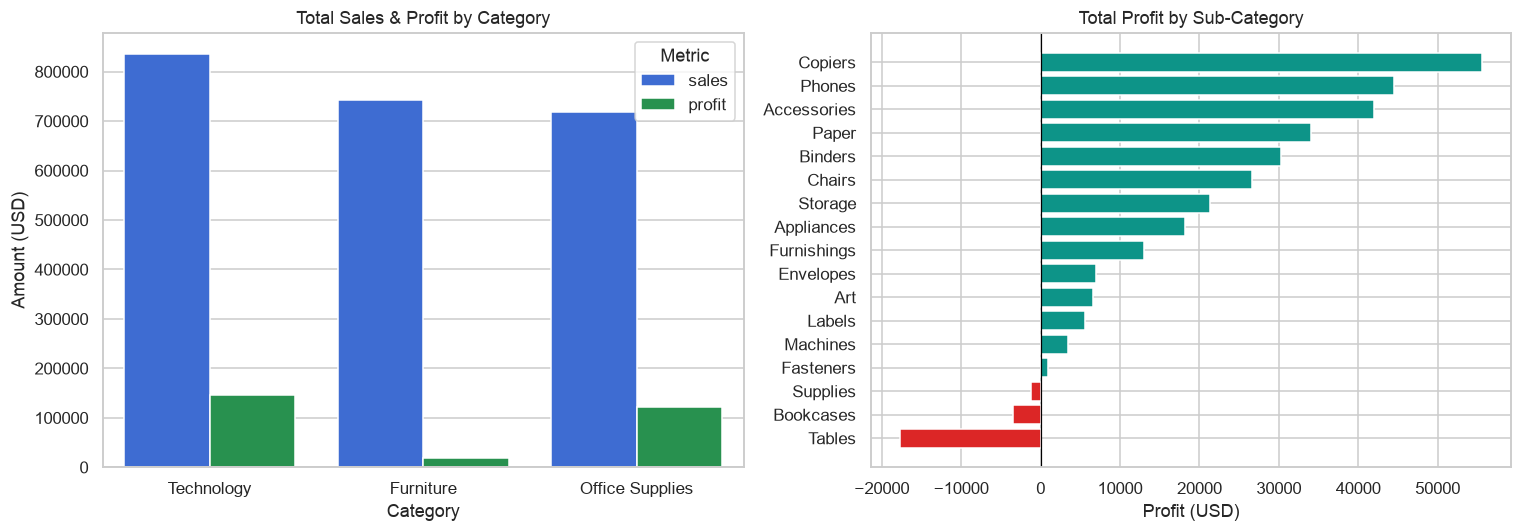

,category,sales,profit
2,Technology,836154.0330,145454.9481
0,Furniture,741718.4233,18463.3316
1,Office Supplies,719047.0320,122490.8008


In [3]:
cat_df = df.groupby("category", as_index=False)[["sales", "profit"]].sum().sort_values("sales", ascending=False)
subcat_df = df.groupby("sub_category", as_index=False)[["sales", "profit"]].sum().sort_values("profit", ascending=True)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

cat_melted = cat_df.melt(id_vars="category", value_vars=["sales", "profit"], var_name="Metric", value_name="USD")
sns.barplot(data=cat_melted, x="category", y="USD", hue="Metric", ax=axes[0], palette=["#2563eb", "#16a34a"])
axes[0].set_title("Total Sales & Profit by Category")
axes[0].set_xlabel("Category")
axes[0].set_ylabel("Amount (USD)")

colors = ["#dc2626" if v < 0 else "#0d9488" for v in subcat_df["profit"]]
axes[1].barh(subcat_df["sub_category"], subcat_df["profit"], color=colors)
axes[1].axvline(0, color="black", linewidth=0.8)
axes[1].set_title("Total Profit by Sub-Category")
axes[1].set_xlabel("Profit (USD)")

plt.tight_layout()
plt.savefig(REPORTS_DIR / "category_performance.png", bbox_inches="tight")
plt.show()
cat_df

## 3. Regional & Segment Analysis

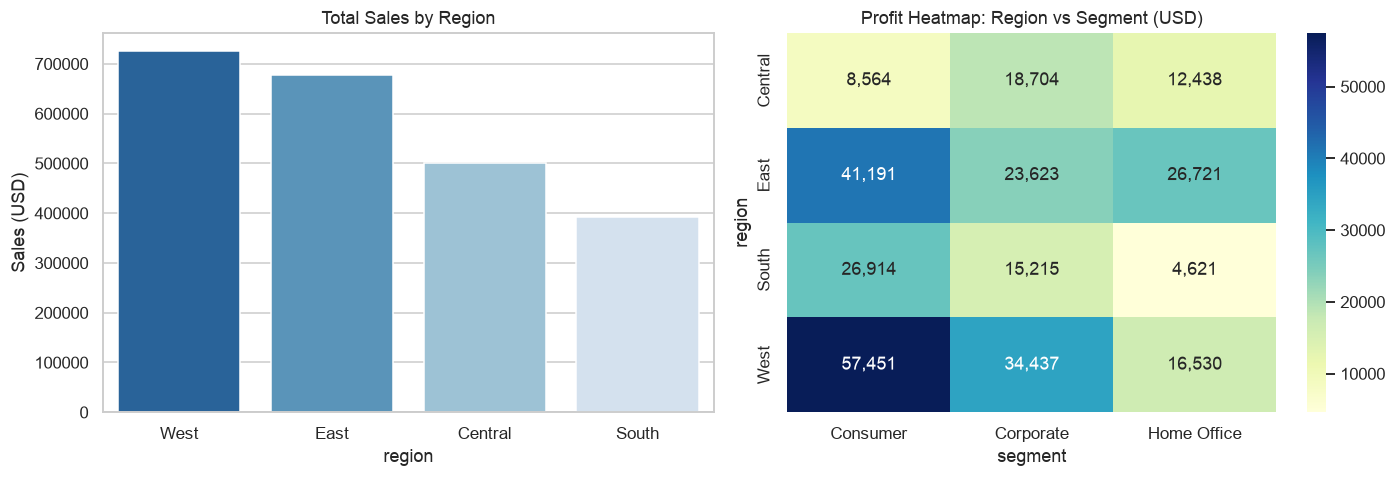

In [4]:
pivot_profit = df.pivot_table(index="region", columns="segment", values="profit", aggfunc="sum")
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

region_sales = df.groupby("region", as_index=False)[["sales", "profit"]].sum().sort_values("sales", ascending=False)
sns.barplot(data=region_sales, x="region", y="sales", hue="region", legend=False, ax=axes[0], palette="Blues_r")
axes[0].set_title("Total Sales by Region")
axes[0].set_ylabel("Sales (USD)")

sns.heatmap(pivot_profit, annot=True, fmt=",.0f", cmap="YlGnBu", ax=axes[1])
axes[1].set_title("Profit Heatmap: Region vs Segment (USD)")

plt.tight_layout()
plt.savefig(REPORTS_DIR / "region_segment_profit.png", bbox_inches="tight")
plt.show()

## 4. Monthly Sales & Profit Trend

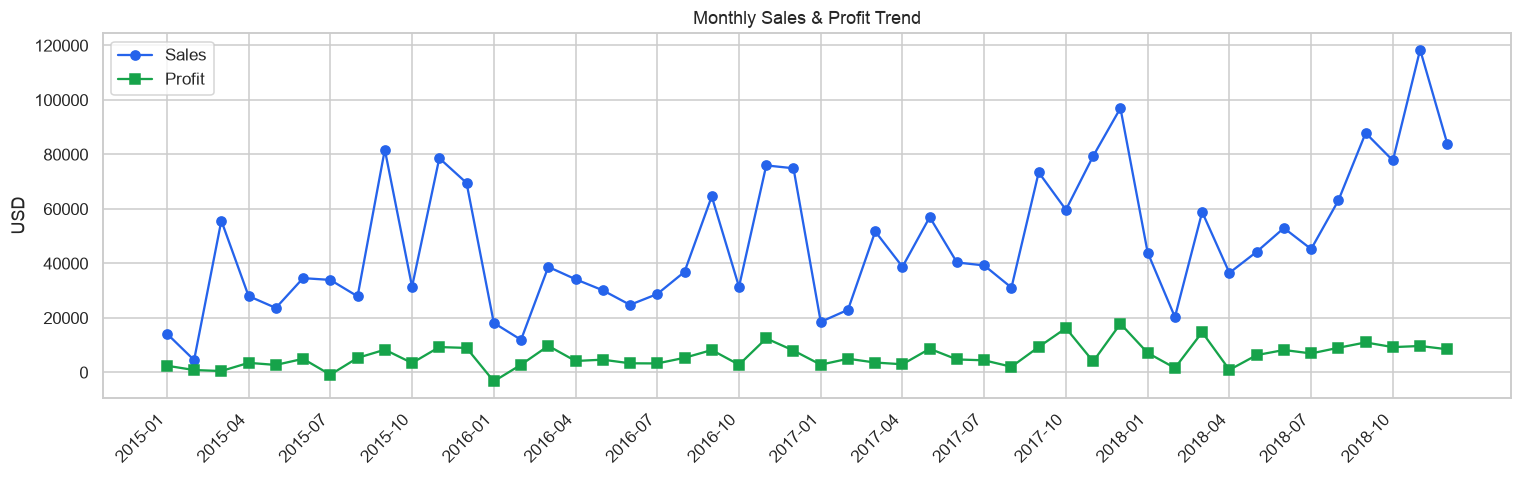

In [5]:
monthly = df.groupby("order_year_month", as_index=False)[["sales", "profit"]].sum().sort_values("order_year_month")
fig, ax = plt.subplots(figsize=(14, 4.5))
ax.plot(monthly["order_year_month"], monthly["sales"], marker="o", label="Sales", color="#2563eb")
ax.plot(monthly["order_year_month"], monthly["profit"], marker="s", label="Profit", color="#16a34a")
ax.set_xticks(range(0, len(monthly), 3))
ax.set_xticklabels(monthly["order_year_month"].iloc[::3], rotation=45, ha="right")
ax.set_title("Monthly Sales & Profit Trend")
ax.set_ylabel("USD")
ax.legend()
plt.tight_layout()
plt.savefig(REPORTS_DIR / "monthly_sales_trend.png", bbox_inches="tight")
plt.show()

## 5. Discount Impact on Profitability

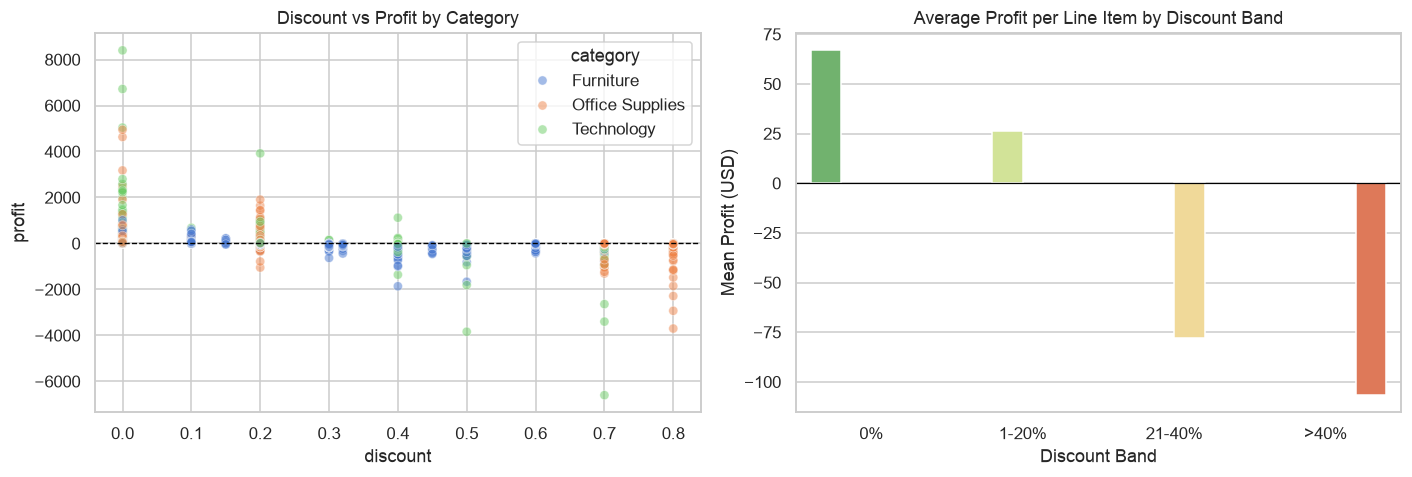

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

sns.scatterplot(data=df, x="discount", y="profit", hue="category", alpha=0.5, ax=axes[0])
axes[0].axhline(0, color="black", linestyle="--", linewidth=0.9)
axes[0].set_title("Discount vs Profit by Category")

disc_summary = df.assign(discount_band=pd.cut(df["discount"], bins=[-0.01, 0, 0.2, 0.4, 1.0], labels=["0%", "1-20%", "21-40%", ">40%"]))
sns.barplot(data=disc_summary, x="discount_band", y="profit", estimator="mean", errorbar=None, hue="discount_band", legend=False, ax=axes[1], palette="RdYlGn_r")
axes[1].axhline(0, color="black", linewidth=0.8)
axes[1].set_title("Average Profit per Line Item by Discount Band")
axes[1].set_xlabel("Discount Band")
axes[1].set_ylabel("Mean Profit (USD)")

plt.tight_layout()
plt.savefig(REPORTS_DIR / "discount_vs_profit.png", bbox_inches="tight")
plt.show()

## 6. SQL Verification via SQLAlchemy

In [7]:
engine = create_engine(f"sqlite:///{(DATA_DIR / 'superstore.db').resolve()}")
query = text("""
    SELECT state,
           COUNT(DISTINCT order_id) AS orders,
           ROUND(SUM(sales), 2) AS total_sales,
           ROUND(SUM(profit), 2) AS total_profit
    FROM orders
    GROUP BY state
    ORDER BY total_sales DESC
    LIMIT 10;
""")
with engine.connect() as conn:
    top_states = pd.read_sql(query, conn)
top_states

,state,orders,total_sales,total_profit
0,California,1021,457687.63,76381.39
1,New York,562,310876.27,74038.55
2,Texas,487,170188.05,-25729.36
3,Washington,256,138641.27,33402.65
4,Pennsylvania,288,116511.91,-15559.96
5,Florida,200,89473.71,-3399.30
6,Illinois,276,80166.10,-12607.89
7,Ohio,236,77976.76,-16959.32
8,Michigan,117,76269.61,24463.19
9,Virginia,115,70636.72,18597.95
